In [52]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.efficientnet import preprocess_input

In [53]:
img_hgt = 224
img_wdt = 224
class_names = ['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']

In [ ]:

# Define the custom layer again
class FixedDense(tf.keras.layers.Dense):
    def __init__(self, *args, **kwargs):
        kwargs.pop('quantization_config', None)  # remove unsupported kwarg
        super().__init__(*args, **kwargs)

try:
    model = tf.keras.models.load_model(
        './Model/effnet_0.82.h5',
        compile=False,
        custom_objects={'FixedDense': FixedDense}  # register custom layer
    )
except Exception as e:
    return f"Error loading model:", str(e)

❌ Error loading model: Error when deserializing class 'Dense' using config={'name': 'dense', 'trainable': True, 'dtype': 'float32', 'units': 320, 'activation': 'relu', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None, 'quantization_config': None}.

Exception encountered: Unrecognized keyword arguments passed to Dense: {'quantization_config': None}


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
2
Raw Predictions: [1.3154672e-08 1.3238130e-07 6.1249202e-06 3.8207315e-08 6.2901329e-09
 9.9999368e-01]
Predicted Class: Snow-Covered
Confidence: 35.22%


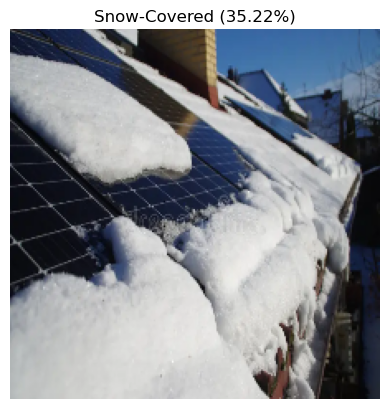

In [58]:
img_dir = "./Test/sonw_1.jpg"
img = cv2.imread(img_dir)

if img is None:
    print(f"Error: Could not load image at {img_dir}")
else:
    # 1. Convert BGR (OpenCV default) to RGB (Model's training format)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # 2. Resize to model's input size
    img_resized = cv2.resize(img_rgb, (img_wdt, img_hgt))
    
    # 3. Use EfficientNet's specific preprocessing
    # Note: For EfficientNet, this typically expects 0-255 pixels.
    # Do NOT divide by 255 manually before this unless your training did so.
    input_arr = np.expand_dims(img_resized, axis=0)
    input_arr = preprocess_input(input_arr)
    
    # 4. Make prediction
    predictions = model.predict(input_arr)
    score = tf.nn.softmax(predictions[0]).numpy()
    print(predicted_index)
    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]
    confidence = 100 * score[predicted_index]
    
    print(f"Raw Predictions: {predictions[0]}")
    print(f"Predicted Class: {predicted_class}")
    print(f"Confidence: {confidence:.2f}%")
    
    # Visualize
    plt.imshow(img_resized)
    plt.title(f"{predicted_class} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()